#EDA on polymarket wallets data.
Goal:figure out good metrics for important measures like win_rate_edge and alike.
Find a good metric to reduce the end sample size from ~80000 to ~5000
    

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [ ]:
df = pd.read_csv("wallets_50+_raw.csv")
df
#step 1 load the file

,wallet,name,sources,n_bets,n_closed,n_unredeemed,n_open_unresolved,wins,losses,win_rate,avg_entry_price,win_rate_edge,total_pnl,total_cost,roi,median_pnl,first_end_date,last_end_date,history_truncated
0,0xf4a2014e45bc166ef71a3d3b43c2c25eb7352b70,thevvault,recent_trader,255,96,159,0,93,162,0.364706,0.280973,0.083733,268.4974,938.325715,0.286145,-1.06440,2026-10-04,2026-10-30,False
1,0x5783429d9824db5fa98821334200d89860ee429d,FUJA10,recent_trader,525,511,14,2,264,261,0.502857,0.457385,0.045472,408.9048,6188.546217,0.066074,0.39940,2026-07-03,2026-11-01,False
2,0x2caf52ce3d5a03c7b3cbcbb1f9d66cfdfaea36f7,NaN,recent_trader,723,723,0,0,254,469,0.351314,0.515044,-0.163730,-502.8452,7393.104096,-0.068015,-0.42840,2025-11-25,2027-01-01,False
3,0xc4825a055595aeac712d35316f62f3a1daa0f0be,avidadeumamao,recent_trader,900,776,124,4,328,572,0.364444,0.386546,-0.022102,-4845.8518,21639.139650,-0.223939,-6.99990,1970-01-01,2027-01-01,False
4,0x8ff4fe30406a3abb2de5829883ac20e5e0d30d50,ottawan,recent_trader,666,659,7,3,278,388,0.417417,0.388222,0.029196,-1500.6389,17289.340027,-0.086796,-1.99990,2026-01-16,2026-11-01,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81794,0xb1f8aa72eeee3316b39716d2d0ae3fdc13aa2734,wegotit2green,leaderboard_all;leaderboard_month,790,790,0,0,386,404,0.488608,0.436589,0.052019,20951.5521,191929.684625,0.109163,-0.10565,2026-02-20,2028-11-08,False
81795,0x63792b1833fb76595e65dd0b91cbd8dea8a8c035,0x63792b1833fB76595e65Dd0b91CBd8dea8a8c035-179...,leaderboard_month;leaderboard_vol_month;leader...,294,183,111,0,144,150,0.489796,0.496882,-0.007086,-8421.3844,396809.775259,-0.021223,-25.27250,2026-10-08,2026-11-07,False
81796,0xc2b50e92aba08ce3a3cb92815c57c84b160f99f7,CRVPicks,market_holder,53,25,28,2,24,29,0.452830,0.473875,-0.021045,-27.6018,1081.512954,-0.025521,-15.39000,2026-09-29,2026-10-31,False
81797,0xfec2354068ceed5766379c53180449e9070c08af,Akareim,leaderboard_month;leaderboard_vol_month;leader...,1413,1295,118,0,651,762,0.460722,0.447657,0.013065,-18297.2540,560647.902071,-0.032636,-15.63500,2025-12-14,2026-10-29,False


In [16]:
df.shape #81799 wallets, 19 columns
df.info
df.describe()
df.columns
print(df.isnull().sum())

wallet                  0
name                 4857
sources                 0
n_bets                  0
n_closed                0
n_unredeemed            0
n_open_unresolved       0
wins                    0
losses                  0
win_rate                0
avg_entry_price         0
win_rate_edge           0
total_pnl               0
total_cost              0
roi                     0
median_pnl              0
first_end_date          0
last_end_date           0
history_truncated       0
dtype: int64


So now with basic information out of the way, we know that the only truly "missing" values are names. This does not impact the result becuase we use the wallet address to determine someones identity. Moving on, we are going to filter the data by removing anomolies. Some other people like Eli might correct the bugged datapoints and rerun the EDA with the updated dataset, but for now we will get all of our conclusions from a filtered version.

Some things to filter out first and foremost:
The share of a bet cannot exceed a dollar, so the average entry price cannot exceed one
Conversely, winrate edge (winrate - average entry price) cannot be a super high number by construction, we will filter out people who have a winrate edge above 1 and under -1

In [ ]:
#check how many bad points there are
print("bad price rows:", (df["avg_entry_price"] > 1).sum()) # 4 bad rows
df = df[df["avg_entry_price"] <= 1]
df.shape 
#now comfirm winrate edge sits between -1 and 1 after this filter
df["win_rate_edge"].min()
df["win_rate_edge"].max()
#both ends are valid, no need to filter out invalid winrate_edges
#THIS IS NOT A END ALL BE ALL SOLUTION, THE PROPER SOLUTION IS TO FIX ENTRIES WITH THE BUGS/ANOMOLIES FOR A COMPELTE PICTURE

bad price rows: 0


np.float64(0.87756)

Next, my goal is to graph the distribution of people who are actually profitable, what their win_rate edge is. I want to see if win_rate edge is correlated or an important factor in having a good return on investment.

profitable wallets: 28992


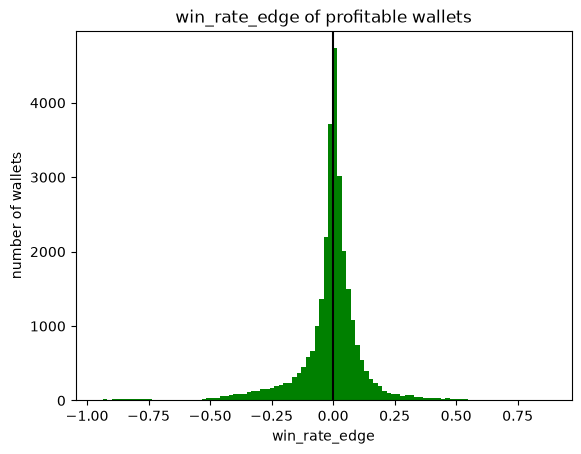

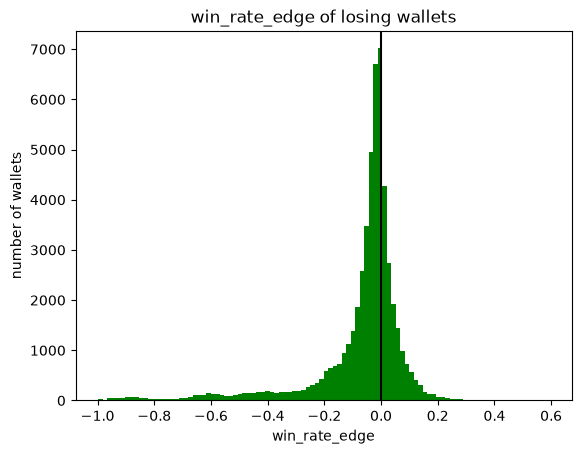

np.float64(-0.0675282519263652)

In [43]:
profitable = df[df["roi"] > 0] #people who earned net money
lost = df[df["roi"] < 0] # people who lost net money
print("profitable wallets:", profitable.shape[0]) # approx ~30% of the data is profitable
plt.hist(profitable["win_rate_edge"], bins = 100, color = "green")
plt.axvline(0, color = "black")
plt.title("win_rate_edge of profitable wallets")
plt.xlabel("win_rate_edge")
plt.ylabel("number of wallets")
plt.show()

plt.hist(lost["win_rate_edge"], bins = 100, color = "green")
plt.axvline(0, color = "black")
plt.title("win_rate_edge of losing wallets")
plt.xlabel("win_rate_edge")
plt.ylabel("number of wallets")
plt.show()
profitable["win_rate_edge"].mean()
lost["win_rate_edge"].mean()


It seems like win_rate edge in relation to wallets is a normal distribution with mean slightly below 0(the average person is slightly worse than just luck). Seeing as a lot of lower end win_rate_edge up to -.25 are profitable, it would be unwise to exclude people who lose more often than they win arbitarily. Likewise, it would be unwise to only look at people with a positive winrate edge as it seems a lot of those people can lose money too. This might indicate "safe betters" betting on high likelyhood events when it is very certain and making near 0 returns because of that and conversely not all longshots are profitable either because of how risky it is.

In the case, we need a way to measure skill. We ask each wallet "if this person were betting completely at random, how far from zero would their edge land just by luck? that distance is standard deviation(standard error)
skill(z)= edge / Standard deviation from luck

z = 0 Performs as good as chance
z = 2; 2 standard deviations above luck , random betting gets this about 2% of the time and is a good measure for skill given we want to keep 5000 samples to look at
z = 4; random chance almost never reaches this, gold standard

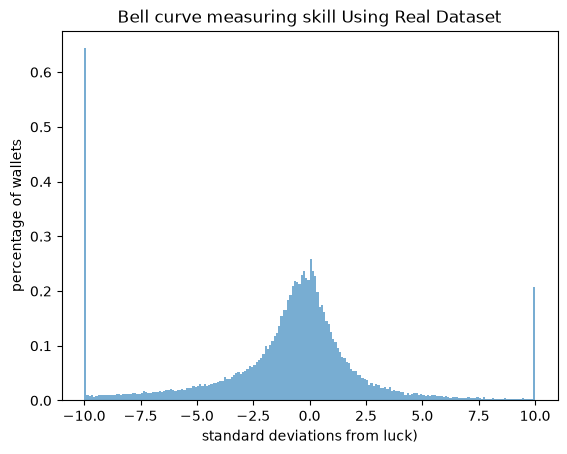

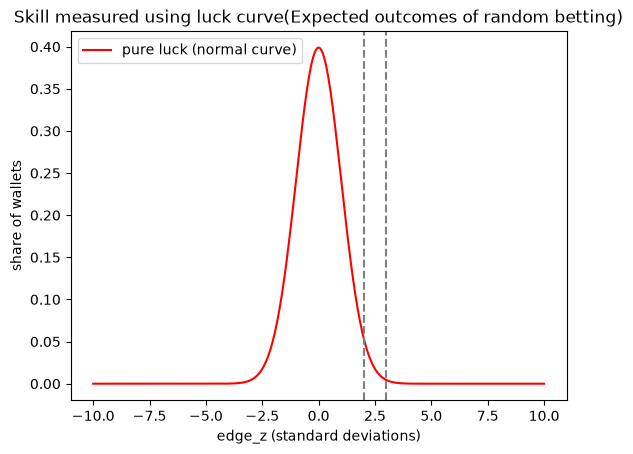

In [56]:
p = df["avg_entry_price"].clip(.01,.99) #avoid boundary bias, at 0 its NAN, at 1 the z score is atrociously unrealistically high
df["edge_z"] = df["win_rate_edge"] / np.sqrt(p * (1 - p)/ df["n_bets"]) #verbatim formula of standard deviation in the bottom
z = df["edge_z"].clip(-10,10) # if its outside of this range chances are they are too clsoe to the boundary bias
plt.hist(z, bins = 200, density = True, alpha = .6, label = "real wallets")
plt.title("Bell curve measuring skill Using Real Dataset")
plt.xlabel("standard deviations from luck)")
plt.ylabel("percentage of wallets")
plt.show()


x = np.linspace(-10, 10, 400)
luck_curve = np.exp(-x**2 / 2) / np.sqrt(2 * np.pi) #modeling if everyone just bet randomly
plt.plot(x, luck_curve, color="red", label="pure luck (normal curve)")

for k in [2, 3]:
    plt.axvline(k, color="gray", linestyle="--")
plt.title("Skill measured using luck curve(Expected outcomes of random betting)")
plt.xlabel("edge_z (standard deviations)")
plt.ylabel("share of wallets")
plt.legend()
plt.show()


the problem with modeling all skilled betters is that they can also be a skilled "loser". There are also a few flaws that could inflate edge_z.
People are allowed to sell their bets early on polymarket when the odds change. Ex// Better A bought at Yes for 30 cents when it was really uncertain and sell at 32 cents when odds change at the slightest, making a slight profit and counting as a "win". If they do that and have high amounts in a loser bet, they can have a high edge while having no/negative gains

# we need to see skilled people who have made money on average as a better metric.

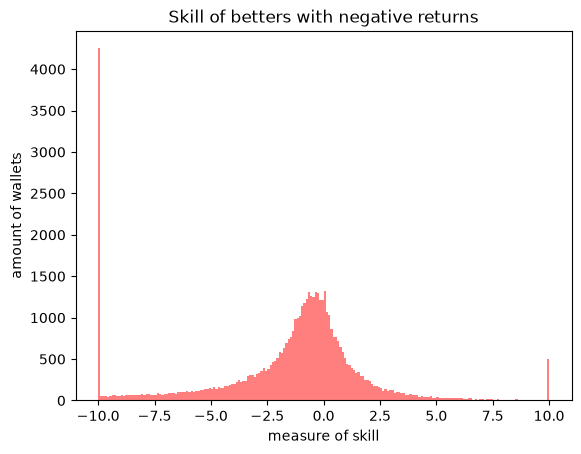

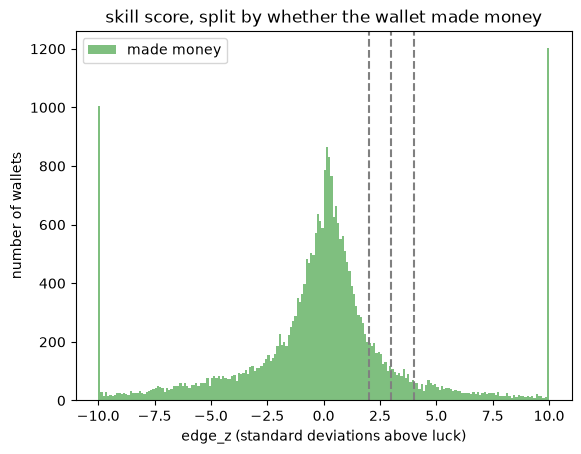

In [65]:
winners = z[df["roi"] > 0]
losers = z[df["roi"] < 0]

plt.hist(losers, bins = 200, alpha = .5, color = "red", label = "lost money")
plt.title("Skill of betters with negative returns")
plt.xlabel("measure of skill")
plt.ylabel("amount of wallets")
plt.show()

plt.hist(winners, bins = 200, alpha = .5, color = "green", label = "made money")
plt.title("Skill of betters with positive returns")
for k in [2, 3, 4]:
    plt.axvline(k, color="gray", linestyle="--")
plt.title("skill score, split by whether the wallet made money")
plt.xlabel("edge_z (standard deviations above luck)")
plt.ylabel("number of wallets")
plt.legend()
plt.show()

Replace Y axis as the number of wallets with ROI to see profit per dollar bet and makes people of all budgets comparable.

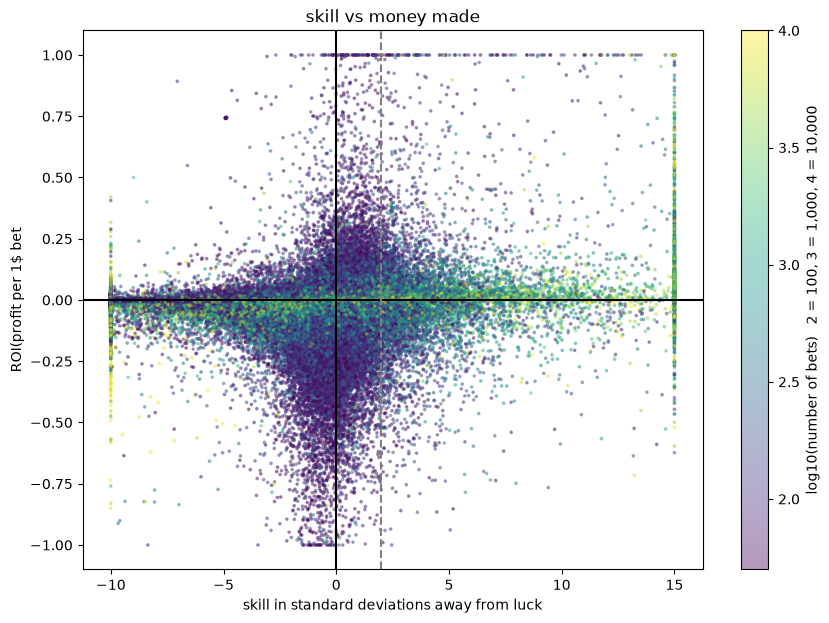

In [75]:

plt.figure(figsize = (10,7))
plt.scatter(df["edge_z"].clip(-10,15),
df["roi"].clip(-1,1),
c = np.log10(df["n_bets"]),
#color = number of bets
s = 3, alpha = .4, cmap = "viridis")
plt.axhline(0, color = "black")
plt.axvline(0, color = "black")
plt.axvline(2, color = "gray", linestyle = "--")
#skill cutoff
plt.title("skill vs money made")
plt.xlabel("skill in standard deviations away from luck")
plt.ylabel("ROI(profit per 1$ bet")
plt.colorbar(label="log10(number of bets)   2 = 100, 3 = 1,000, 4 = 10,000")
plt.show()

There are still a few pressing issues with the data, mainly:
1."skilled losers" can still have good signals because that person still wins more often than the price implies. So if you copied their picks with your own bet size it could work
2. What has made people money will not carry over to you because you may not be able to copy their timing, they may of gotten in when it was more uncertain and by the time you got to the bet, the price has increased and a lot of the edge is gone. Bigshots move the price by themselves with enough capital.
3. We cannot account if the person has "sold early" or not
4. We do not know for certain who is a market maket/bots, bots can execute huge amount of trades combined with selling early inflates their z score but makes their trades near uncopyable because they do not hold and they are the type of bots to make many microtrades per second

For now we can make top 5000 wallets of the most important factors seen in the data before and backtest them in the modeling section.

The following:
1.Skilled winners (main list)
2.Skilled, winners or losers(benchmark)
3. Skilled losers (experiment, more optional)
With slight judgement calls to remove

In [80]:
#do an even filter on every data point
quality = df[(df["total_cost"] >= 500) #judgement call to filter out people without a stake or skin in the game, they spend too little
             & (df["history_truncated"] == False)
             & (df["last_end_date"] >= "2026-08-01")]
print("before quality filters:", len(df))
print("after quality filters:", len(quality))


# the three groups
skilled = quality["edge_z"] > 2

skilled_winners = quality[skilled & (quality["roi"] > 0)]
skilled_losers  = quality[skilled & (quality["roi"] <= 0)]
all_skilled     = quality[skilled]

print("skilled winners:", len(skilled_winners))
print("skilled losers:", len(skilled_losers))
print("all skilled:", len(all_skilled))

skilled_winners.to_csv("group_skilled_winners.csv", index=False)
skilled_losers.to_csv("group_skilled_losers.csv", index=False)
all_skilled.to_csv("group_all_skilled.csv", index=False)

#best to not lower the bar to reach 5k entries using edge_z > 2 and roi > 0+ quality filters, Only 44% of skilled wallets lost money

before quality filters: 81795
after quality filters: 63708
skilled winners: 4062
skilled losers: 3209
all skilled: 7271
